# 04 - Fine-tune BrainOmni on the combined cohort

Direct test of the sensor-level conclusion. Fine-tuning underperformed there, and the learning
curves pointed to 148 subjects being too few to adapt the backbone. Pooling the OSF and parcel
cohorts roughly doubles that, so this asks whether fine-tuning works once the data constraint
is loosened.

Protocol matches `notebooks_withseed/02_finetune_tiny` exactly (differential learning rates, AdamW,
warmup-cosine, label smoothing, nested 5-fold CV, seed 123, best epoch by inner-validation loss),
so results are directly comparable to the sensor-only numbers.

**Overlap caveat.** If the two cohorts share subjects, fine-tuning on the pool would train on a
person in one representation and test on them in another, inflating accuracy through leakage rather
than through extra data. Set `SUBJECT_GROUPS` once the mapping is known; the outer CV then keeps
repeated subjects in the same fold.

**Cost.** Roughly double the sensor-only run: about 15 hours for tiny, 40+ for base. Start with
tiny. Checkpointing and resume are built in, so an interrupted run picks up where it stopped.

In [18]:
import os, sys, json, math, random, time, datetime
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'
import numpy as np, torch
import torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split, StratifiedKFold, StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
sys.path.insert(0, '/Users/faenegoro/Documents/Neuroimaging/BrainOmni')
from brainomni.model import BrainOmni

def set_seed(seed=123):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
set_seed(123)

device = torch.device('mps') if torch.backends.mps.is_available() else torch.device('cpu')
MODEL, SUFFIX = 'base', 'cortical'          # base run: expect 40+ hours, see markdown above
HDIM   = 256 if MODEL == 'tiny' else 512
sfx    = '_base' if MODEL == 'base' else ''
OSF, OUT = '../data/preprocessed', '../results_parcel'
CKPT_ROOT = '/Users/faenegoro/Documents/Neuroimaging/BrainOmni/ckpt_collection'
os.makedirs(OUT, exist_ok=True)

BACKBONE_LR, HEAD_LR = 1e-5, 1e-4
EPOCHS_BY_NF = {10: 400, 9: 200, 8: 200}    # last-1 needs longer to converge
N_FROZEN_LIST = [10, 9, 8]                  # full depth sweep: last-1, last-2, last-3
                                            # tiny took ~11h in practice; base is a larger
                                            # backbone, budget 40+ hours total
SUBJECT_GROUPS = None                       # set if the cohorts overlap

LOG_FILE = f'{OUT}/train_log_combined_{MODEL}.txt'
def log(msg):
    line = f'[{datetime.datetime.now():%H:%M:%S}] {msg}'
    print(line, flush=True)
    with open(LOG_FILE, 'a') as f: f.write(line + '\n')
log(f'combined fine-tune | model={MODEL} | device={device}')

[01:35:48] combined fine-tune | model=base | device=mps


In [19]:
osf1 = np.load(f'{OSF}/proj_out1{sfx}.npy'); osf2 = np.load(f'{OSF}/proj_out2{sfx}.npy')
osf_y = np.load(f'{OSF}/labels.npy')
par1 = np.load(f'{OUT}/parcel_proj_out1_{MODEL}_{SUFFIX}.npy')
par2 = np.load(f'{OUT}/parcel_proj_out2_{MODEL}_{SUFFIX}.npy')
par_y = np.load(f'{OUT}/parcel_labels_{SUFFIX}.npy')

assert osf1.shape[1:] == par1.shape[1:], (
    f'token shape mismatch {osf1.shape[1:]} vs {par1.shape[1:]}. '
    f'Did notebook 01 run with MODEL={MODEL}?')

proj_out1 = np.concatenate([osf1, par1]).astype(np.float32)
proj_out2 = np.concatenate([osf2, par2]).astype(np.float32)
labels    = np.concatenate([osf_y, par_y])
source    = np.array(['osf'] * len(osf_y) + ['parcel'] * len(par_y))
N = len(labels)
log(f'combined {N} subjects (OSF {len(osf_y)} + parcel {len(par_y)}) | '
    f'AD {int((labels==1).sum())} Control {int((labels==0).sum())}')
log(f'proj_out {proj_out1.shape}')

[01:35:52] combined 309 subjects (OSF 148 + parcel 161) | AD 155 Control 154
[01:35:52] proj_out (309, 16, 160, 512)


In [20]:
model_config = json.load(open(f'{CKPT_ROOT}/{MODEL}/model_cfg.json'))
base_checkpoint = torch.load(f'{CKPT_ROOT}/{MODEL}/BrainOmni.pt', map_location='cpu', weights_only=True)

class CachedMEGDataset(Dataset):
    def __init__(self, idx, c1, c2, y): self.i, self.c1, self.c2, self.y = idx, c1, c2, y
    def __len__(self): return len(self.i)
    def __getitem__(self, k):
        j = self.i[k]
        return self.c1[j], self.c2[j], torch.tensor(self.y[j], dtype=torch.long)

class FinetuneClassifier(nn.Module):
    def __init__(self, blocks, hidden_dim=HDIM):
        super().__init__(); self.blocks = blocks
        self.head = nn.Sequential(nn.Linear(hidden_dim*16, 128), nn.ReLU(),
                                  nn.Dropout(0.3), nn.Linear(128, 2))
    def forward(self, x1, x2):
        x1, x2 = x1.to(device), x2.to(device)
        for b in self.blocks: x1 = b(x1); x2 = b(x2)
        x1 = F.normalize(x1, p=2.0, dim=-1, eps=1e-6).mean(dim=2)
        x2 = F.normalize(x2, p=2.0, dim=-1, eps=1e-6).mean(dim=2)
        return self.head(((x1 + x2) / 2).flatten(1))

def make_warmup_cosine(opt, total, warm=0.1, wmin=0.1, cmin=0.1):
    ws = max(1, int(total * warm))
    def f(s):
        if s < ws: return wmin + (1 - wmin) * s / ws
        p = (s - ws) / max(1, total - ws)
        return cmin + (1 - cmin) * 0.5 * (1 + math.cos(math.pi * p))
    return torch.optim.lr_scheduler.LambdaLR(opt, f)

def fresh_frozen_model():
    m = BrainOmni(**model_config); m.load_state_dict(base_checkpoint, strict=False)
    for p in m.parameters(): p.requires_grad = False
    return m.to(device).eval()

def cache_frozen(model, n_frozen):
    c1, c2 = [], []
    with torch.no_grad():
        for i in range(N):
            x1 = torch.tensor(proj_out1[i]).unsqueeze(0).to(device)
            x2 = torch.tensor(proj_out2[i]).unsqueeze(0).to(device)
            for b in list(model.blocks)[:n_frozen]: x1 = b(x1); x2 = b(x2)
            c1.append(x1.squeeze(0).cpu()); c2.append(x2.squeeze(0).cpu())
    return c1, c2

def extract_features(model, ft_blocks, n_frozen):
    feats = []
    with torch.no_grad():
        for i in range(N):
            x1 = torch.tensor(proj_out1[i]).unsqueeze(0).to(device)
            x2 = torch.tensor(proj_out2[i]).unsqueeze(0).to(device)
            for b in list(model.blocks)[:n_frozen]: x1 = b(x1); x2 = b(x2)
            for b in ft_blocks: x1 = b(x1); x2 = b(x2)
            x1 = F.normalize(x1, p=2.0, dim=-1, eps=1e-6).mean(dim=2).flatten(1)
            x2 = F.normalize(x2, p=2.0, dim=-1, eps=1e-6).mean(dim=2).flatten(1)
            feats.append(((x1 + x2) / 2).squeeze(0).cpu().numpy())
    return np.array(feats)
log('helpers ready')

[01:35:52] helpers ready


In [21]:
def train_finetune(n_frozen, tr_idx, va_idx, c1, c2, model, max_epochs, monitor_idx=None):
    # No explicit generator: shuffling draws from the global RNG seeded by set_seed(123),
    # matching notebooks_withseed so the numbers stay comparable.
    tl = DataLoader(CachedMEGDataset(tr_idx, c1, c2, labels), batch_size=8, shuffle=True)
    vl = DataLoader(CachedMEGDataset(va_idx, c1, c2, labels), batch_size=8)
    mn = DataLoader(CachedMEGDataset(monitor_idx, c1, c2, labels), batch_size=8) if monitor_idx is not None else None

    unfrozen = nn.ModuleList(list(model.blocks)[n_frozen:-1])
    for p in unfrozen.parameters(): p.requires_grad = True
    ft = FinetuneClassifier(unfrozen, HDIM).to(device)
    opt = torch.optim.AdamW([
        {'params': ft.blocks.parameters(), 'lr': BACKBONE_LR, 'weight_decay': 0.05},
        {'params': ft.head.parameters(),   'lr': HEAD_LR,     'weight_decay': 0.05}],
        betas=(0.9, 0.99), eps=1e-6)
    sched = make_warmup_cosine(opt, max_epochs * len(tl))
    crit  = nn.CrossEntropyLoss(label_smoothing=0.1)

    def ev(loader):
        ft.eval(); p, t, ls = [], [], 0.0
        with torch.no_grad():
            for x1, x2, y in loader:
                o = ft(x1, x2); ls += crit(o, y.to(device)).item()
                p.extend(o.argmax(1).cpu().numpy()); t.extend(y.numpy())
        return accuracy_score(t, p), ls / len(loader)

    best_vl, best_ep, best_w = float('inf'), 0, None
    hist = {k: [] for k in ['train_accs','val_accs','train_losses','val_losses','mon_accs','mon_losses']}
    for ep in range(max_epochs):
        ft.train(); preds, trues, el = [], [], 0.0
        for x1, x2, y in tl:
            opt.zero_grad(); o = ft(x1, x2); loss = crit(o, y.to(device)); loss.backward()
            torch.nn.utils.clip_grad_norm_(ft.parameters(), 1.0); opt.step(); sched.step()
            el += loss.item(); preds.extend(o.argmax(1).cpu().numpy()); trues.extend(y.numpy())
        hist['train_accs'].append(accuracy_score(trues, preds)); hist['train_losses'].append(el/len(tl))
        va, vll = ev(vl); hist['val_accs'].append(va); hist['val_losses'].append(vll)
        if mn is not None:
            ma, mll = ev(mn); hist['mon_accs'].append(ma); hist['mon_losses'].append(mll)
        if vll < best_vl - 1e-4:
            best_vl, best_ep = vll, ep + 1
            best_w = {k: v.clone() for k, v in ft.state_dict().items()}
    if best_w is not None: ft.load_state_dict(best_w)
    hist['best_ep'] = best_ep
    return ft, hist

def nn_predict(ft, idx, c1, c2):
    ft.eval(); preds, probs = [], []
    with torch.no_grad():
        for i in idx:
            o = ft(c1[i].unsqueeze(0), c2[i].unsqueeze(0))
            probs.append(torch.softmax(o, 1)[0, 1].item()); preds.append(o.argmax(1).item())
    return np.array(preds), np.array(probs)
log('trainer ready')

[01:35:52] trainer ready


In [22]:
def get_folds(seed=123, n_splits=5):
    if SUBJECT_GROUPS is None:
        return list(StratifiedKFold(n_splits, shuffle=True, random_state=seed).split(np.arange(N), labels))
    return list(StratifiedGroupKFold(n_splits, shuffle=True, random_state=seed)
                .split(np.arange(N), labels, groups=SUBJECT_GROUPS))

def run_cv(n_frozen, cv_epochs, ckpt_path, seed=123, inner_val=0.15):
    """Nested 5-fold CV, checkpointed after every fold.

    A crash mid-config resumes from the last completed fold rather than restarting, which
    matters here because a single config is a 15 hour run.
    """
    folds = get_folds(seed)
    blank = {'nn_pred': np.zeros(N, int), 'nn_prob': np.zeros(N),
             'lr_pred': np.zeros(N, int), 'lr_prob': np.zeros(N),
             'nn_folds': [], 'lr_folds': [], 'fold_hist': [], 'done_folds': []}

    all_state = torch.load(ckpt_path, map_location='cpu', weights_only=False) if os.path.exists(ckpt_path) else {}
    partial = all_state.get('partial', {})
    st = partial.get(n_frozen, blank)
    if st['done_folds']:
        log(f'  resuming last-{11-n_frozen}: folds {st["done_folds"]} already done')

    for fold, (tr, te) in enumerate(folds):
        if fold in st['done_folds']:
            continue
        # Seed per fold so a resumed run reproduces an uninterrupted one exactly.
        # Without this, folds after a restart would see different RNG state.
        set_seed(seed + fold)
        inner_tr, inner_va = train_test_split(tr, test_size=inner_val,
                                              stratify=labels[tr], random_state=seed)
        model = fresh_frozen_model(); c1, c2 = cache_frozen(model, n_frozen)
        ft, hist = train_finetune(n_frozen, inner_tr, inner_va, c1, c2, model, cv_epochs, monitor_idx=te)

        yp, ypr = nn_predict(ft, te, c1, c2)
        st['nn_pred'][te], st['nn_prob'][te] = yp, ypr
        st['nn_folds'].append(accuracy_score(labels[te], yp))

        feats = extract_features(model, ft.blocks, n_frozen)
        lr = LogisticRegression(max_iter=1000).fit(feats[tr], labels[tr])
        st['lr_pred'][te] = lr.predict(feats[te]); st['lr_prob'][te] = lr.predict_proba(feats[te])[:, 1]
        st['lr_folds'].append(accuracy_score(labels[te], st['lr_pred'][te]))
        st['fold_hist'].append(hist); st['done_folds'].append(fold)

        # Persist immediately: this fold's work is now safe from a crash.
        partial[n_frozen] = st
        all_state['partial'] = partial
        all_state['labels'] = labels; all_state['source'] = source
        torch.save(all_state, ckpt_path)
        log(f'  n_frozen={n_frozen} fold {fold+1}/{len(folds)}: best_ep {hist["best_ep"]} | '
            f'NN {st["nn_folds"][-1]:.3f} | LR {st["lr_folds"][-1]:.3f} | checkpointed')

    return {'nn_mean': float(np.mean(st['nn_folds'])), 'nn_folds': st['nn_folds'],
            'lr_mean': float(np.mean(st['lr_folds'])), 'lr_folds': st['lr_folds'],
            'y_true': labels, 'nn_pred': st['nn_pred'], 'nn_prob': st['nn_prob'],
            'lr_pred': st['lr_pred'], 'lr_prob': st['lr_prob'], 'fold_hist': st['fold_hist']}
log('CV helper ready (fold-level checkpointing)')

[01:35:52] CV helper ready (fold-level checkpointing)


In [ ]:
RESUME = True
CKPT = f'{OUT}/finetune_combined_{MODEL}.pt'
cv_results = {}
if RESUME and os.path.exists(CKPT):
    _prev = torch.load(CKPT, map_location='cpu', weights_only=False)
    cv_results = _prev.get('cv', {})
    if cv_results: log(f'configs already complete: {sorted(cv_results.keys())}')

log(f'PROVENANCE seed=123 torch={torch.__version__} backbone_lr={BACKBONE_LR} head_lr={HEAD_LR}')
log(f'PROVENANCE N={N} grouped_cv={SUBJECT_GROUPS is not None} epochs={EPOCHS_BY_NF}')

for n_frozen in N_FROZEN_LIST:
    if n_frozen in cv_results:
        log(f'=== last-{11-n_frozen} block(s): SKIP (complete) ==='); continue
    ep = EPOCHS_BY_NF[n_frozen]
    log(f'=== 5-fold CV | last-{11-n_frozen} block(s) | {ep} epochs | {N} subjects ===')
    t0 = time.time()
    cv_results[n_frozen] = run_cv(n_frozen, ep, CKPT)
    log(f'   NN mean {cv_results[n_frozen]["nn_mean"]:.3f} | '
        f'LR mean {cv_results[n_frozen]["lr_mean"]:.3f} | {(time.time()-t0)/60:.1f} min')
    _all = torch.load(CKPT, map_location='cpu', weights_only=False) if os.path.exists(CKPT) else {}
    _all['cv'] = cv_results; _all['labels'] = labels; _all['source'] = source
    torch.save(_all, CKPT)
    log(f'   config complete, saved -> {os.path.basename(CKPT)}')
log('=== done ===')

[01:35:52] PROVENANCE seed=123 torch=2.12.0 backbone_lr=1e-05 head_lr=0.0001
[01:35:52] PROVENANCE N=309 grouped_cv=False epochs={10: 400, 9: 200, 8: 200}
[01:35:52] === 5-fold CV | last-1 block(s) | 400 epochs | 309 subjects ===


/opt/miniconda3/envs/brainomni/lib/python3.11/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


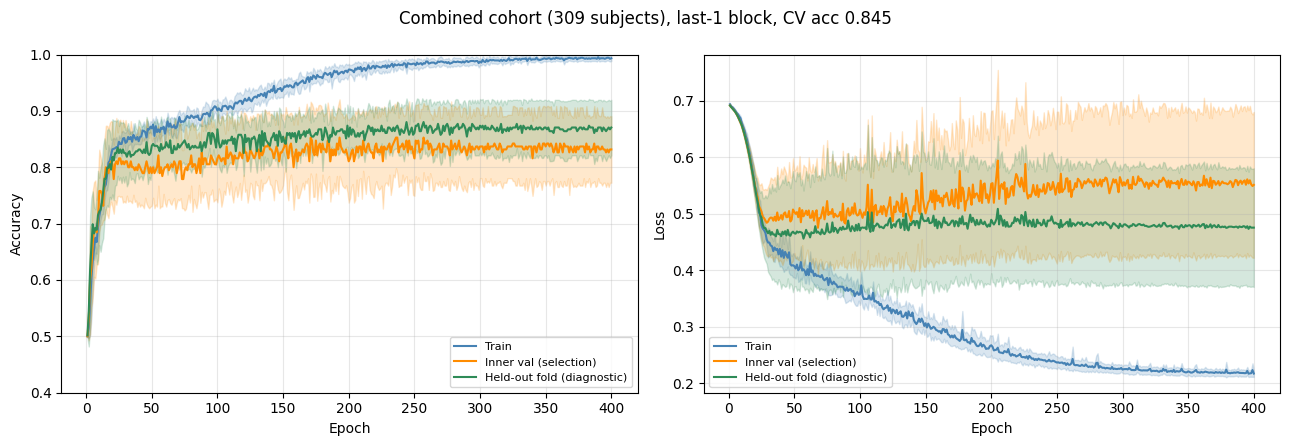

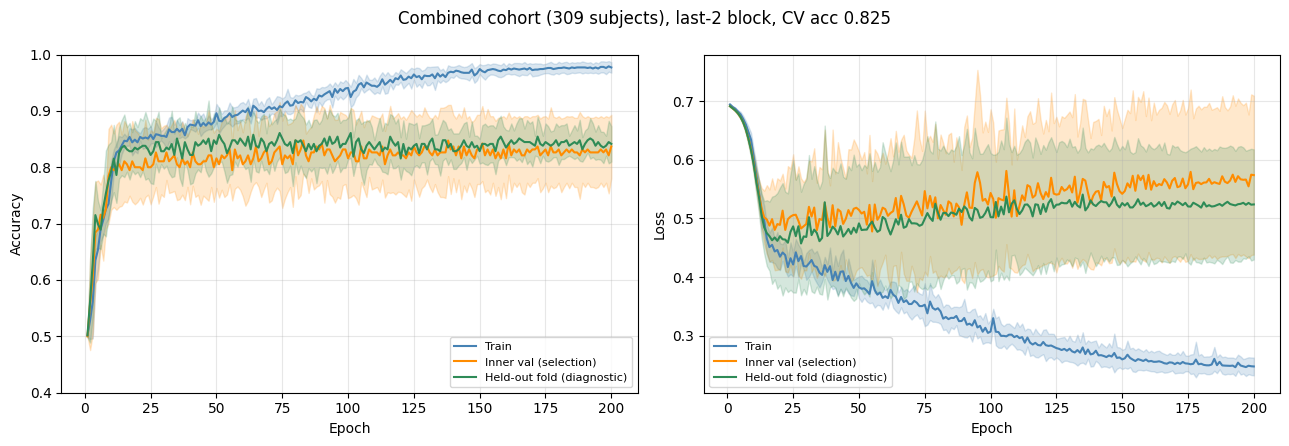

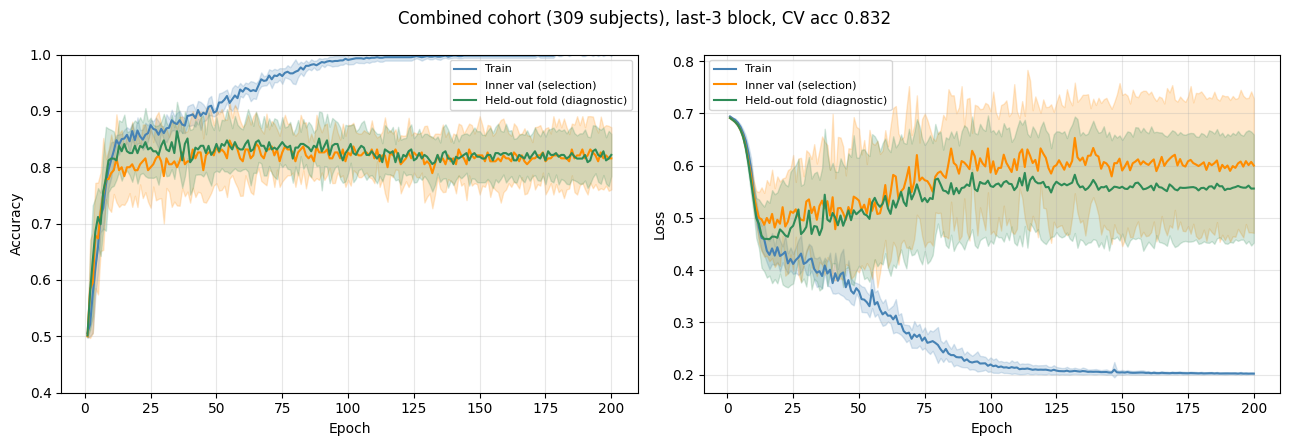

If held-out loss rises later (or less) than in the sensor-only run, the extra data
genuinely reduced overfitting.


In [ ]:
# Learning curves: with more data, overfitting should be less severe than the
# sensor-only run, where held-out loss rose after roughly epoch 25-50.
import matplotlib.pyplot as plt

for nf in sorted(cv_results, reverse=True):
    hs = cv_results[nf]['fold_hist']
    if not hs: continue
    L = min(len(h['train_losses']) for h in hs)
    ep = np.arange(1, L + 1)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    def band(ax, key, color, label):
        M = np.array([h[key][:L] for h in hs if len(h[key]) >= L])
        if M.size == 0: return
        m, s = M.mean(0), M.std(0)
        ax.plot(ep, m, color=color, label=label)
        ax.fill_between(ep, m - s, m + s, color=color, alpha=0.2)
    band(axes[0], 'train_accs', 'steelblue',  'Train')
    band(axes[0], 'val_accs',   'darkorange', 'Inner val (selection)')
    band(axes[0], 'mon_accs',   'seagreen',   'Held-out fold (diagnostic)')
    axes[0].set_ylabel('Accuracy'); axes[0].set_ylim(0.4, 1.0)
    band(axes[1], 'train_losses', 'steelblue',  'Train')
    band(axes[1], 'val_losses',   'darkorange', 'Inner val (selection)')
    band(axes[1], 'mon_losses',   'seagreen',   'Held-out fold (diagnostic)')
    axes[1].set_ylabel('Loss')
    for a in axes: a.set_xlabel('Epoch'); a.legend(fontsize=8); a.grid(alpha=0.3)
    fig.suptitle(f'Combined cohort ({N} subjects), last-{11-nf} block, '
                 f'CV acc {cv_results[nf]["nn_mean"]:.3f}', fontsize=12)
    plt.tight_layout()
    plt.savefig(f'{OUT}/combined_curves_last{11-nf}_{MODEL}.png', dpi=150); plt.show()
print('If held-out loss rises later (or less) than in the sensor-only run, the extra data')
print('genuinely reduced overfitting.')

In [ ]:
# Does more data rescue fine-tuning? Compare against the sensor-only results.
print(f'Combined cohort ({N} subjects), fine-tuned BrainOmni-{MODEL}:')
for nf in sorted(cv_results, reverse=True):
    r = cv_results[nf]
    print(f'  last-{11-nf} block(s): NN {r["nn_mean"]:.3f} | LR {r["lr_mean"]:.3f}')

print(f'\nSensor-only reference (148 subjects, {MODEL}):')
ref = {'tiny': (0.790, 0.797), 'base': (0.817, 0.817)}[MODEL]
print(f'  last-1 block: NN {ref[0]:.3f} | LR {ref[1]:.3f}')
print(f'  frozen + LR: 0.831   |   handcrafted + LR: 0.872')

best = max(r['nn_mean'] for r in cv_results.values()) if cv_results else 0
print()
if best > 0.872:
    print('Fine-tuning now beats the handcrafted baseline. Doubling the data changed the')
    print('conclusion, which is a substantial result for the paper.')
elif best > 0.831:
    print('Fine-tuning now beats the frozen baseline but not handcrafted. More data helped,')
    print('though not enough to overturn the headline finding.')
elif best > ref[0] + 0.02:
    print('Improved over the sensor-only fine-tune but still below both baselines.')
    print('Directionally consistent with data being the constraint.')
else:
    print('No meaningful improvement. Doubling the data did not rescue fine-tuning, which')
    print('points at the representation rather than sample size as the limitation.')
    print('Note this is confounded if the pooled cohorts differ in representation quality.')

Combined cohort (309 subjects), fine-tuned BrainOmni-tiny:
  last-1 block(s): NN 0.845 | LR 0.838
  last-2 block(s): NN 0.825 | LR 0.848
  last-3 block(s): NN 0.832 | LR 0.845

Sensor-only reference (148 subjects, tiny):
  last-1 block: NN 0.790 | LR 0.797
  frozen + LR: 0.831   |   handcrafted + LR: 0.872

Fine-tuning now beats the frozen baseline but not handcrafted. More data helped,
though not enough to overturn the headline finding.
